# GENIE BPC Prostate v1.0-public — questions Pr1–Pr3

Source: Jacob's *CBIO thoughts* deck, slides 25–27 (context: Parabilis' ERG degrader). Data: AACR Project GENIE BPC Prostate v1.0-public (Synapse).

Conventions as in `README.md`. **ERG-altered** = any ERG alteration: structural variant / fusion (TMPRSS2-ERG and other partners), non-synonymous
mutation, amplification or deep deletion. Fusions dominate. **Detection caveat:** DNA panels differ in whether and how they call the TMPRSS2-ERG
rearrangement, so ERG-fusion frequency is partly a panel artefact. Centres / panels that never report an ERG structural variant are listed and the
analyses are repeated within panels that do.

In [1]:
import sys, re, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cbio_lib.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cbio_lib as cb

cb.setup_plots()
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.3g}".format
pd.options.display.width = 200
DS = "bpc_prostate"
F = []

b = cb.BPC("Prostate")
pd.Series(b.summary())

cohort                            Prostate
patients                              1116
index_cancers                         1116
patients_with_2+_index_cancers           0
samples                               1227
samples_used                          1116
regimens                              5439
mutations_nonsyn                      6717
cna_profiled_samples                  1065
sv_rows                               1178
dtype: object

## Data pin

In [2]:
log = pd.read_csv(cb.DATA / "genie" / "download_log.csv")
print("release_version:", b.index.release_version.unique())
log[log.cohort == "Prostate"][[c for c in ["category", "filename", "synapse_id", "version", "md5"] if c in log.columns]]

release_version: ['1.0-public']


,category,filename,synapse_id,version,md5
76,docs,GENIE BPC Prostate v1.0-public Analytic Data G...,syn73719286,1,ac6fe3d49aadbb2a51b668b11faff1d8
77,docs,GENIE BPC Prostate v1.0-public Variable Synops...,syn73719287,1,0976174fd1833e22b2ba35498394dba1
78,docs,GENIE BPC Prostate v1.0-public Release Notes.pdf,syn73719285,1,f40b897c40af2c52c07f952690539579
79,analytic,patient_level_dataset.csv,syn73963159,1,a46c876d457bd63a7640e784a63b2f90
80,analytic,cancer_level_dataset_index.csv,syn73963154,1,7c2e26ae52bb8f8046a3a786e3537edc
81,analytic,cancer_level_dataset_non_index.csv,syn73963156,1,6c30d8ed9b49e7ad7bc605cab04947e1
82,analytic,cancer_panel_test_level_dataset.csv,syn73963160,1,f918d5fb3193bdf6634f53605c5c74cb
83,analytic,regimen_cancer_level_dataset.csv,syn73963155,1,65e2072b7836d8c61dcd26ae2ab83448
84,analytic,imaging_level_dataset.csv,syn73963151,1,321c9e17727a732e604aa3b3fc21d7f8
85,analytic,med_onc_note_level_dataset.csv,syn73963152,1,25b8224585a1670161abc15a434b1463


## Cohort and alteration matrix

,step,n,dropped
0,Patients in release,1116,0
1,Index prostate cancer (first index cancer per ...,1116,0
2,With a sequenced sample of the index cancer,1116,0
3,With OS from diagnosis,1116,0


0 patients had two index cancers (first used); 0 samples with unknown panel; 29 patients with sequencing report after last follow-up (dropped from left-truncated models only).
Deaths: 424 / 1116.  Median OS from dx: 156.7 months.


stage_dx
Stage IV           428
Stage II           351
Stage III          279
Stage I             43
Stage I-III NOS     14
Name: stage_dx, dtype: int64

,gene,kind,n_altered,n_tested,pct
0,TMPRSS2,fus,267,955,28
1,TP53,mut,266,1116,23.8
2,ERG,fus,217,955,22.7
3,AR,amp,119,954,12.5
4,KMT2D,mut,108,1087,9.9
5,FOXA1,mut,106,801,13.2
6,PTEN,homdel,104,954,10.9
7,SPOP,mut,87,832,10.5
8,ATM,mut,86,1116,7.7
9,PTEN,mut,77,1116,6.9


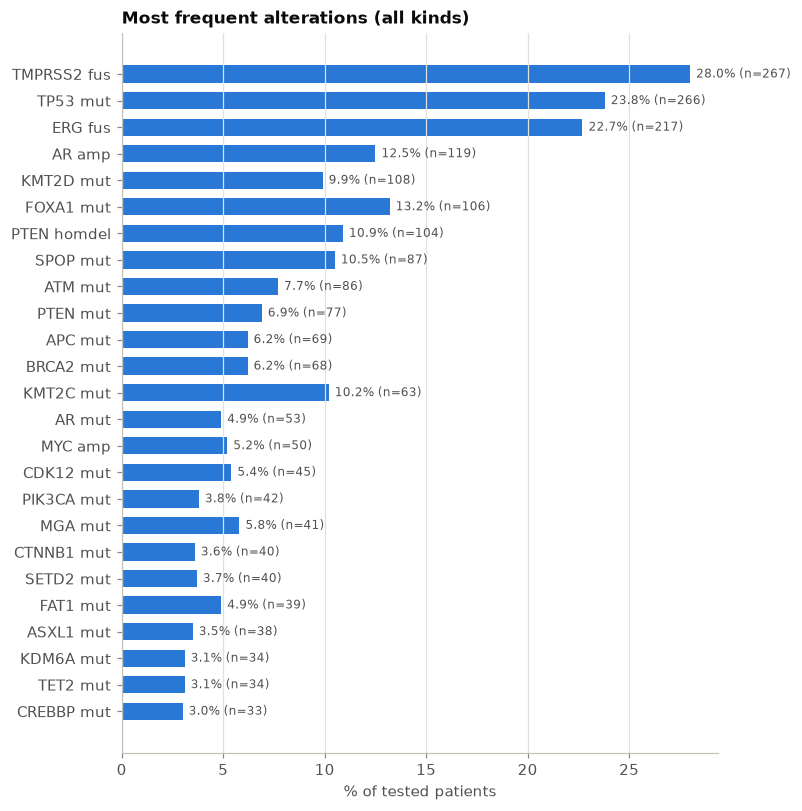

In [3]:
S = b.survival_dx()
A = b.alterations()
display(cb.consort([
    ("Patients in release", len(b.patients)),
    ("Index prostate cancer (first index cancer per patient)", len(b.index)),
    ("With a sequenced sample of the index cancer", int(S.entry.notna().sum())),
    ("With OS from diagnosis", int(S.time.notna().sum())),
]))
print(f"{b.n_multi_index} patients had two index cancers (first used); {A.n_unknown_panel} samples with unknown panel; "
      f"{int((S.entry >= S.time).sum())} patients with sequencing report after last follow-up (dropped from left-truncated models only).")
print(f"Deaths: {int(S.event.sum())} / {len(S)}.  Median OS from dx: {cb.km_table(S.assign(g='all'), 'g').median_months[0]} months.")
display(S.stage_dx.value_counts().rename("stage_dx"))
freq = A.frequency(kinds=("mut", "amp", "homdel", "fus"))
ax = cb.bar_freq(freq[freq.kind.isin(["mut", "fus", "amp", "homdel"])], top=25, title="Most frequent alterations (all kinds)")
cb.save(DS, "cohort", table=freq, fig=ax.figure, slug="gene_frequency")
freq.head(20)

## Pr1 — Characterise ERG alterations
Frequency by alteration kind, by panel (detection caveat), fusion partners, and OS of ERG-altered vs not.

fus        217
mut          5
amp          1
homdel       0
any        222
tested    1040
Name: ERG-altered patients, dtype: int64

col_0,no ERG fusion,ERG fusion,pct_fusion
patient_id,,,
VICC-01-T7,18,9,33.3
DFCI-ONCOPANEL-3,115,55,32.4
MSK-IMPACT468,228,85,27.2
MSK-IMPACT410,147,43,22.6
DFCI-ONCOPANEL-3.1,32,7,17.9
MSK-IMPACT341,51,7,12.1
DFCI-ONCOPANEL-2,114,11,8.8
DFCI-ONCOPANEL-1,132,0,0
UHN-48-V1,23,0,0


TMPRSS2       243
INTERGENIC      2
Name: ERG fusion partner (samples), dtype: int64

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR,HR_lo,HR_hi,p_cox
0,ERG not altered,818,316,155,0.988,0.943,0.805,0.884,NaN,NaN,NaN,NaN
1,ERG altered,222,84,145,0.991,0.966,0.854,0.884,1.14,0.897,1.46,0.277


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR,HR_lo,HR_hi,p_cox
0,ERG not altered,700,272,153,0.985,0.938,0.806,0.865,NaN,NaN,NaN,NaN
1,ERG altered,222,84,145,0.991,0.966,0.854,0.865,1.05,0.818,1.34,0.708


[Pr1] descriptive: ERG altered in 222/1040 patients (21.3%; fusions 217, mutations 5, amp 1). Fusion frequency ranges 0.0–33.3% across panels (detection artefact). OS, detecting panels only: median 145.0 vs 152.8 mo, p=0.865, adjusted HR (LT) 1.05.


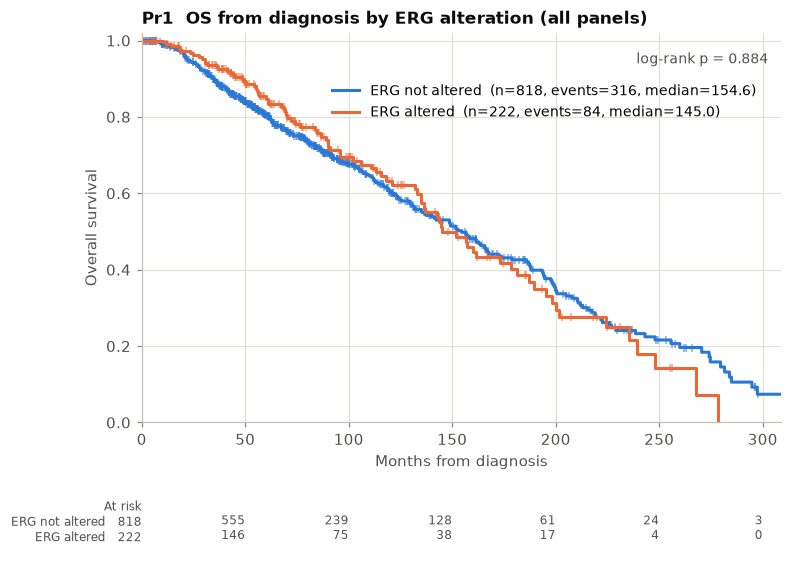

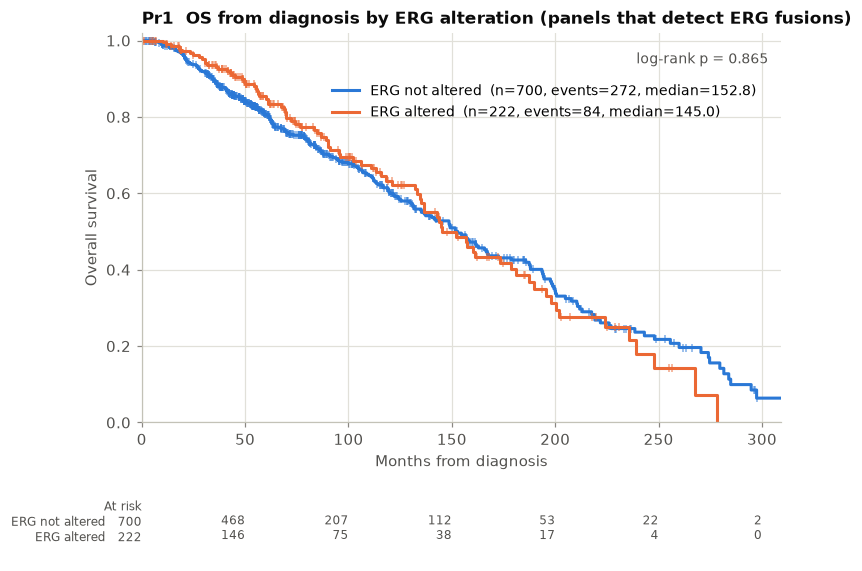

In [4]:
erg_kinds = {k: A.status("ERG", k) for k in ["fus", "mut", "amp", "homdel"]}
erg = A.status("ERG", "alt")
display(pd.Series({k: int(v.sum()) for k, v in erg_kinds.items()} | {"any": int(erg.sum()), "tested": len(erg)}).rename("ERG-altered patients"))
panel = S.index.to_series().map(A.sample_of).map(b.panel_of)
by_panel = (pd.crosstab(panel, erg_kinds["fus"].reindex(S.index).fillna(False)).rename(columns={False: "no ERG fusion", True: "ERG fusion"})
            .reindex(columns=["no ERG fusion", "ERG fusion"], fill_value=0))
by_panel["pct_fusion"] = (100 * by_panel["ERG fusion"] / by_panel.sum(axis=1)).round(1)
display(by_panel.sort_values("pct_fusion", ascending=False))
sv_erg = b.sv_long[b.sv_long.gene == "ERG"]
partners = b.sv_raw
if "Site1_Hugo_Symbol" in partners.columns:
    pe = partners[(partners.Site1_Hugo_Symbol == "ERG") | (partners.Site2_Hugo_Symbol == "ERG")]
    partner = np.where(pe.Site1_Hugo_Symbol == "ERG", pe.Site2_Hugo_Symbol, pe.Site1_Hugo_Symbol)
    display(pd.Series(partner).fillna("intragenic / unknown").value_counts().head(10).rename("ERG fusion partner (samples)"))
detecting_panels = by_panel.index[by_panel["ERG fusion"] > 0]
S["panel"] = panel
S["erg_detecting_panel"] = S.panel.isin(detecting_panels)
d, t1 = cb.compare(S, erg, labels=("ERG not altered", "ERG altered"), entry="entry")
ax, _ = cb.km_plot(d, "group", order=["ERG not altered", "ERG altered"], title="Pr1  OS from diagnosis by ERG alteration (all panels)", xlabel="Months from diagnosis")
cb.save(DS, "Pr1", table=t1, fig=ax.figure, slug="erg_vs_not_all_panels")
display(t1)
d2, t1b = cb.compare(S[S.erg_detecting_panel], erg, labels=("ERG not altered", "ERG altered"), entry="entry", adjust=["stage_dx", "age_dx"])
ax, _ = cb.km_plot(d2, "group", order=["ERG not altered", "ERG altered"], title="Pr1  OS from diagnosis by ERG alteration (panels that detect ERG fusions)", xlabel="Months from diagnosis")
cb.save(DS, "Pr1", table=t1b, fig=ax.figure, slug="erg_vs_not_detecting_panels")
display(t1b)
cb.save(DS, "Pr1", table=by_panel.reset_index(), slug="erg_fusion_by_panel")
cb.finding("Pr1", "descriptive",
           f"ERG altered in {int(erg.sum())}/{len(erg)} patients ({100 * erg.mean():.1f}%; fusions {int(erg_kinds['fus'].sum())}, mutations {int(erg_kinds['mut'].sum())}, amp {int(erg_kinds['amp'].sum())}). "
           f"Fusion frequency ranges {by_panel.pct_fusion.min()}–{by_panel.pct_fusion.max()}% across panels (detection artefact). "
           f"OS, detecting panels only: median {t1b.median_months[1]} vs {t1b.median_months[0]} mo, p={cb.fmt_p(t1b.p_logrank[0])}, adjusted HR (LT) {t1b.attrs['HR']:.2f}.", F)

## Pr2 (replicate) — Among ERG-altered patients, AR vs PTEN co-alteration shows no significant OS difference
Within ERG-altered patients: AR co-alteration (amplification or mutation) vs PTEN co-alteration (deep deletion or mutation) vs neither (slides 26–27).
cBioPortal's comparison dropped patients with both; here they are their own group.

profile
neither            130
PTEN co-altered     46
AR co-altered       33
AR + PTEN           13
Name: ERG-altered patients, dtype: int64

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,neither,130,26,187,1,0.974,0.878,0.000756
1,AR co-altered,33,26,145,1,1,0.876,0.000756
2,PTEN co-altered,46,21,90.2,0.955,0.908,0.808,0.000756
3,AR + PTEN,13,11,95.8,1,1,0.769,0.000756


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR_LT_pten_vs_ar
0,AR co-altered,33,26,145,1,1,0.876,0.0559,0.433
1,PTEN co-altered,46,21,90.2,0.955,0.908,0.808,0.0559,0.433


[Pr2] replicated: ERG-altered: AR co-altered n=33 median 144.6 vs PTEN co-altered n=46 median 90.2 mo, log-rank p=0.056, HR (LT) PTEN vs AR 0.43. Four-group log-rank p=7.6e-04. AR amplification marks castration resistance acquired under therapy, so the AR group is enriched for late-sequenced patients.


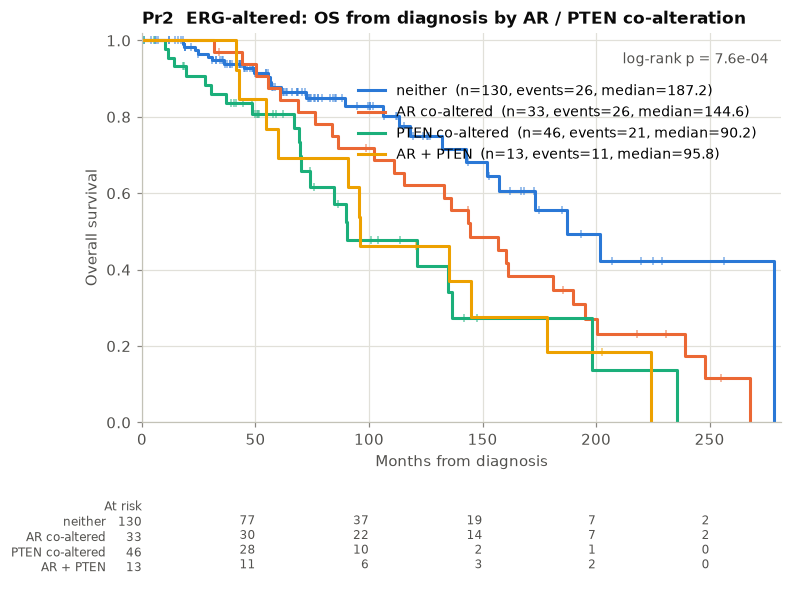

In [5]:
erg_ids = erg.index[erg]
ar = (A.status("AR", "amp") | A.status("AR", "mut")).rename("AR")
pten = (A.status("PTEN", "homdel") | A.status("PTEN", "mut")).rename("PTEN")
st = pd.concat([ar, pten], axis=1, join="inner").loc[lambda x: x.index.isin(erg_ids)]
st["profile"] = np.select([st.AR & st.PTEN, st.AR, st.PTEN], ["AR + PTEN", "AR co-altered", "PTEN co-altered"], default="neither")
order2 = ["neither", "AR co-altered", "PTEN co-altered", "AR + PTEN"]
d = S.join(st.profile, how="inner")
display(d.profile.value_counts().rename("ERG-altered patients"))
ax, t2 = cb.km_plot(d, "profile", order=order2, title="Pr2  ERG-altered: OS from diagnosis by AR / PTEN co-alteration", xlabel="Months from diagnosis")
cb.save(DS, "Pr2", table=t2, fig=ax.figure, slug="ar_vs_pten_in_erg")
display(t2)
dx = d[d.profile.isin(["AR co-altered", "PTEN co-altered"])]
t2x = cb.km_table(dx, "profile", order=["AR co-altered", "PTEN co-altered"])
h2 = cb.hr(dx.assign(feat=(dx.profile == "PTEN co-altered")), "feat", entry="entry")
t2x["HR_LT_pten_vs_ar"] = h2["HR"]
cb.save(DS, "Pr2", table=t2x, slug="ar_vs_pten_two_groups")
display(t2x)
# AR amplification is a marker of castration resistance (acquired under ADT): sequencing after progression inflates its apparent effect
cb.finding("Pr2", "replicated" if t2x.p_logrank[0] > 0.05 else "not replicated",
           f"ERG-altered: AR co-altered n={t2x.n[0]} median {t2x.median_months[0]} vs PTEN co-altered n={t2x.n[1]} median {t2x.median_months[1]} mo, "
           f"log-rank p={cb.fmt_p(t2x.p_logrank[0])}, HR (LT) PTEN vs AR {h2['HR']:.2f}. Four-group log-rank p={cb.fmt_p(t2.p_logrank[0])}. "
           f"AR amplification marks castration resistance acquired under therapy, so the AR group is enriched for late-sequenced patients.", F)

## Pr3 — Mutational profiles that convey higher risk in ERG-altered patients
Systematic screen of every co-alteration within ERG-altered patients (≥ 10 carriers / non-carriers), log-rank, left-truncated Cox HR, BH FDR;
repeated in panels that detect ERG fusions. Then the same screen in ERG-wild-type patients, to separate ERG-specific from general prognostic markers.

,feature,n_alt,median_alt,median_wt,HR_erg,p_logrank_erg,q_bh_erg,HR_wt,p_logrank_wt,q_bh_wt
0,TP53 mut,79,95.6,187,2.73,6.18e-07,6.79e-06,2.37,1.24e-05,0.0019
1,PTEN homdel,42,95.6,160,2.43,0.000371,0.00204,2.96,0.0203,0.165
2,KMT2D mut,18,106,157,1.72,0.0118,0.0432,1.26,0.244,0.553
3,AR amp,39,133,173,4.04,0.036,0.099,5.85,6.57e-05,0.00337
4,FAT1 mut,10,121,157,2.43,0.0557,0.123,1.16,0.15,0.412
5,ATM mut,14,248,145,0.525,0.141,0.258,1.61,0.0441,0.226
6,PTEN mut,17,137,152,1.4,0.413,0.631,1.36,0.551,0.719
7,APC mut,14,89.2,152,1.98,0.459,0.631,1.82,0.303,0.587
8,MGA mut,10,187,145,0.932,0.67,0.818,1.14,0.943,0.988
9,FOXA1 mut,13,145,157,0.412,0.82,0.872,1.48,0.0369,0.219


[Pr3] signal: ERG-altered n=222, 11 features tested. FDR<0.1: TP53 mut (n=79) HR 2.73 q=6.8e-06, PTEN homdel (n=42) HR 2.43 q=0.002, KMT2D mut (n=18) HR 1.72 q=0.043, AR amp (n=39) HR 4.04 q=0.099. ERG-specific if absent from the ERG-wt screen: PTEN homdel, KMT2D mut.


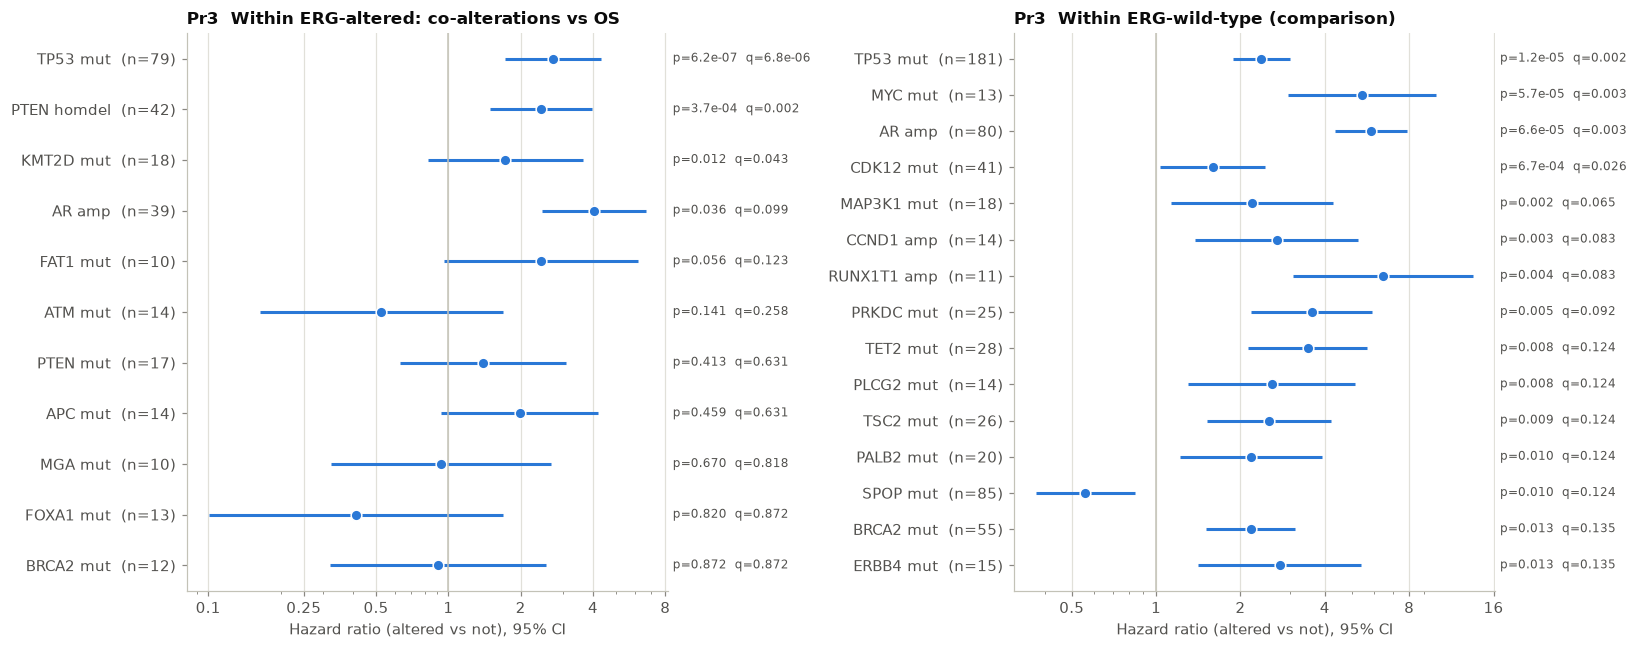

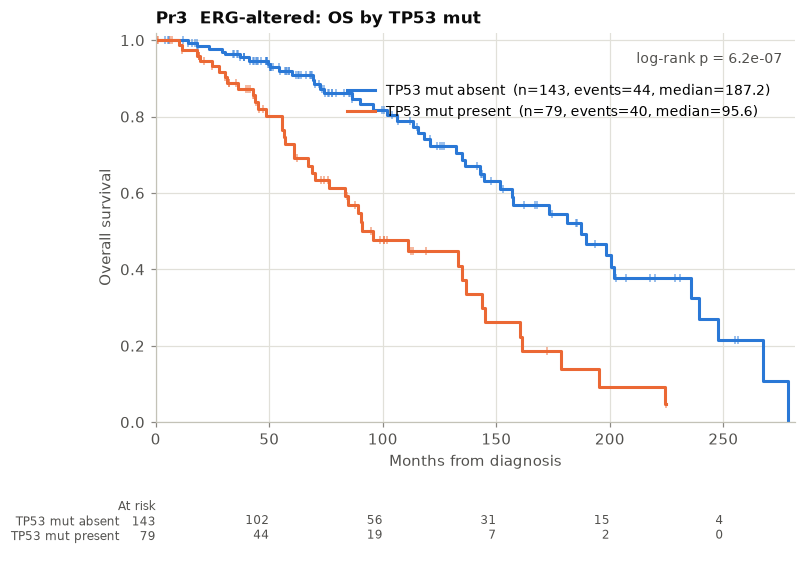

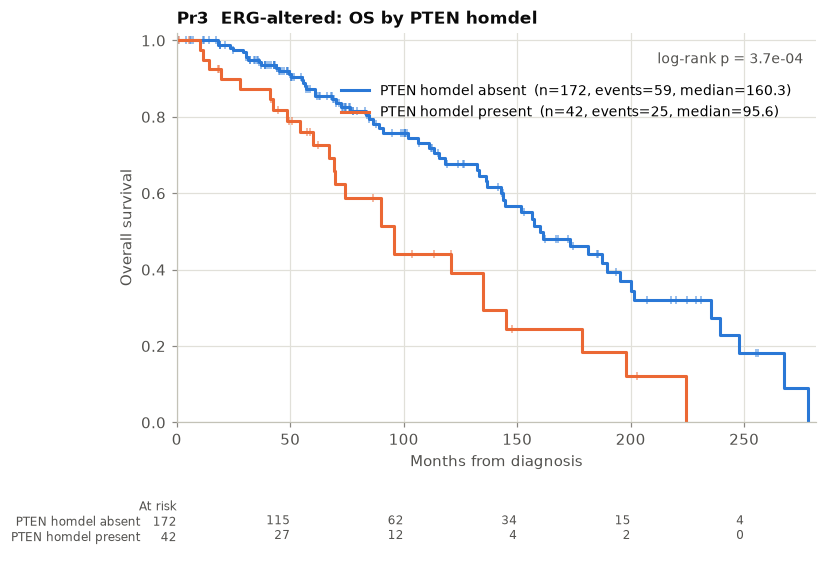

In [6]:
scr = cb.gene_screen(S, A, kinds=("mut", "amp", "homdel", "fus"), min_n=10, entry="entry", patients=erg_ids)
scr = scr[scr.gene != "ERG"].reset_index(drop=True)
scr_wt = cb.gene_screen(S, A, kinds=("mut", "amp", "homdel", "fus"), min_n=10, entry="entry", patients=erg.index[~erg])
scr_wt = scr_wt[scr_wt.gene != "ERG"].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cb.forest_plot(scr, top=15, title="Pr3  Within ERG-altered: co-alterations vs OS", ax=axes[0])
cb.forest_plot(scr_wt, top=15, title="Pr3  Within ERG-wild-type (comparison)", ax=axes[1])
fig.tight_layout()
cb.save(DS, "Pr3", table=scr, fig=fig, slug="screen_in_erg_altered")
cb.save(DS, "Pr3", table=scr_wt, slug="screen_in_erg_wt")
both = scr.merge(scr_wt[["feature", "HR", "p_logrank", "q_bh"]], on="feature", how="left", suffixes=("_erg", "_wt"))
display(both.head(15)[["feature", "n_alt", "median_alt", "median_wt", "HR_erg", "p_logrank_erg", "q_bh_erg", "HR_wt", "p_logrank_wt", "q_bh_wt"]])
hits = scr[scr.q_bh < 0.1]
for r in hits.head(2).itertuples():
    d, t = cb.compare(S.loc[erg_ids], A.status(r.gene, r.kind), labels=(f"{r.feature} absent", f"{r.feature} present"), entry="entry")
    ax, _ = cb.km_plot(d, "group", order=[f"{r.feature} absent", f"{r.feature} present"], title=f"Pr3  ERG-altered: OS by {r.feature}", xlabel="Months from diagnosis")
    cb.save(DS, "Pr3", table=t, fig=ax.figure, slug=f"erg_by_{r.gene}_{r.kind}")
cb.finding("Pr3", "signal" if len(hits) else "no signal at FDR<0.1",
           f"ERG-altered n={len(erg_ids)}, {len(scr)} features tested. FDR<0.1: " +
           (", ".join(f"{r.feature} (n={r.n_alt}) HR {r.HR:.2f} q={r.q_bh:.2g}" for r in hits.itertuples()) or f"none (best {scr.feature[0]} HR {scr.HR[0]:.2f} p={cb.fmt_p(scr.p_logrank[0])})") +
           ". ERG-specific if absent from the ERG-wt screen: " +
           (", ".join(r.feature for r in both[(both.q_bh_erg < 0.1) & ((both.q_bh_wt >= 0.1) | both.q_bh_wt.isna())].itertuples()) or "none") + ".", F)

## Summary of findings

In [7]:
fd = pd.DataFrame(F)
cb.save(DS, "findings", table=fd)
pd.set_option("display.max_colwidth", 400)
fd

,question,verdict,note
0,Pr1,descriptive,"ERG altered in 222/1040 patients (21.3%; fusions 217, mutations 5, amp 1). Fusion frequency ranges 0.0–33.3% across panels (detection artefact). OS, detecting panels only: median 145.0 vs 152.8 mo, p=0.865, adjusted HR (LT) 1.05."
1,Pr2,replicated,"ERG-altered: AR co-altered n=33 median 144.6 vs PTEN co-altered n=46 median 90.2 mo, log-rank p=0.056, HR (LT) PTEN vs AR 0.43. Four-group log-rank p=7.6e-04. AR amplification marks castration resistance acquired under therapy, so the AR group is enriched for late-sequenced patients."
2,Pr3,signal,"ERG-altered n=222, 11 features tested. FDR<0.1: TP53 mut (n=79) HR 2.73 q=6.8e-06, PTEN homdel (n=42) HR 2.43 q=0.002, KMT2D mut (n=18) HR 1.72 q=0.043, AR amp (n=39) HR 4.04 q=0.099. ERG-specific if absent from the ERG-wt screen: PTEN homdel, KMT2D mut."
